# 15 · Duplicate candidates are not merge decisions

## The engineering question
When does high semantic similarity hide an entity mismatch or a contradictory statement?

**Learning outcomes:** calibrate a candidate threshold on development pairs; freeze it before a separate entity-family test; compare exact text, embedding candidates, and typed-field verification; count false merges explicitly.

We generate fictional record pairs from disjoint device names in development and test. A positive pair describes the same serial-numbered device. Negative pairs differ in serial identity or explicitly disagree about whether power is supplied. This lab evaluates candidate generation and a conservative verifier, not a universal entity-resolution system. Candidate similarity is evidence to inspect, not permission to merge records destructively.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("15", "B", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


,split,left,right,same_entity,similarity
0,development,Atlas device serial 100 provides power over Et...,"Power over Ethernet is provided by Atlas, seri...",True,0.941065
1,development,Atlas device serial 100 provides power over Et...,Atlas device serial 100 provides power over Et...,True,1.000000
2,development,Atlas device serial 100 provides power over Et...,Atlas device serial 101 provides power over Et...,False,0.970078
3,development,Atlas device serial 100 provides power over Et...,Atlas device serial 100 does not provide power...,False,0.869607
4,development,Boreal device serial 100 provides power over E...,"Power over Ethernet is provided by Boreal, ser...",True,0.940599
5,development,Boreal device serial 100 provides power over E...,Boreal device serial 100 provides power over E...,True,1.000000
6,development,Boreal device serial 100 provides power over E...,Boreal device serial 101 provides power over E...,False,0.962456
7,development,Boreal device serial 100 provides power over E...,Boreal device serial 100 does not provide powe...,False,0.825423
8,test,Cobalt device serial 100 provides power over E...,"Power over Ethernet is provided by Cobalt, ser...",True,0.953753
9,test,Cobalt device serial 100 provides power over E...,Cobalt device serial 100 provides power over E...,True,1.000000


,split,method,tp,fp,fn,tn,precision,recall,f1
0,development,exact text,2,0,2,4,1.000000,0.5,0.666667
1,development,semantic candidates,4,2,0,2,0.666667,1.0,0.800000
2,development,typed verification,4,0,0,4,1.000000,1.0,1.000000
3,test,exact text,2,0,2,4,1.000000,0.5,0.666667
4,test,semantic candidates,4,2,0,2,0.666667,1.0,0.800000
5,test,typed verification,4,0,0,4,1.000000,1.0,1.000000


Frozen development-selected threshold: 0.9393103448275861


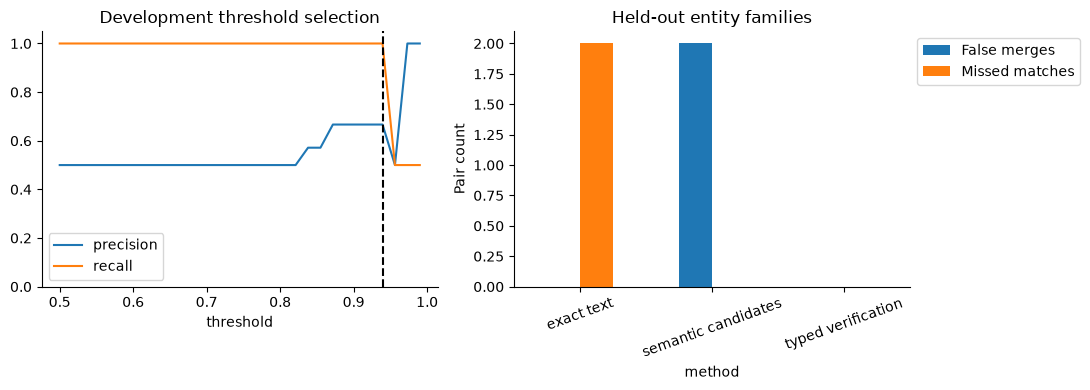

In [2]:
from vector_masterclass.models import embed
from vector_masterclass.applications import binary_metrics

pairs = []
for split, names in [("development", ["Atlas", "Boreal"]), ("test", ["Cobalt", "Delta"])]:
    for name in names:
        base = f"{name} device serial 100 provides power over Ethernet."
        pairs.extend(
            [
                {
                    "split": split,
                    "family": name,
                    "left": base,
                    "right": f"Power over Ethernet is provided by {name}, serial 100.",
                    "same_entity": True,
                    "left_serial": "100",
                    "right_serial": "100",
                    "compatible_claim": True,
                },
                {
                    "split": split,
                    "family": name,
                    "left": base,
                    "right": base,
                    "same_entity": True,
                    "left_serial": "100",
                    "right_serial": "100",
                    "compatible_claim": True,
                },
                {
                    "split": split,
                    "family": name,
                    "left": base,
                    "right": f"{name} device serial 101 provides power over Ethernet.",
                    "same_entity": False,
                    "left_serial": "100",
                    "right_serial": "101",
                    "compatible_claim": True,
                },
                {
                    "split": split,
                    "family": name,
                    "left": base,
                    "right": f"{name} device serial 100 does not provide power over Ethernet.",
                    "same_entity": False,
                    "left_serial": "100",
                    "right_serial": "100",
                    "compatible_claim": False,
                },
            ]
        )
vectors = embed([text for p in pairs for text in [p["left"], p["right"]]])
for i, pair in enumerate(pairs):
    pair["similarity"] = float(vectors[2 * i] @ vectors[2 * i + 1])
frame = pd.DataFrame(pairs)
dev = frame[frame.split.eq("development")]
sweep = pd.DataFrame(
    [
        {"threshold": float(t), **binary_metrics(dev.same_entity, dev.similarity.ge(t))}
        for t in np.linspace(0.5, 0.99, 30)
    ]
)
chosen = (
    sweep.sort_values(["f1", "precision", "threshold"], ascending=[False, False, False])
    .iloc[0]
    .threshold
)
rows = []
for split, group in frame.groupby("split"):
    candidates = group.similarity.ge(chosen)
    # The typed compatibility flag is supplied by the source schema, not inferred by cosine.
    verified = candidates & group.left_serial.eq(group.right_serial) & group.compatible_claim
    for method, predicted in [
        ("exact text", group.left.eq(group.right)),
        ("semantic candidates", candidates),
        ("typed verification", verified),
    ]:
        rows.append(
            {"split": split, "method": method, **binary_metrics(group.same_entity, predicted)}
        )
results = lesson.table(pd.DataFrame(rows))
lesson.table(frame, "pairs")
lesson.table(sweep, "development-thresholds")
display(frame[["split", "left", "right", "same_entity", "similarity"]])
display(results)
print("Frozen development-selected threshold:", chosen)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sweep.plot(x="threshold", y=["precision", "recall"], ax=axes[0])
axes[0].axvline(chosen, color="black", linestyle="--")
axes[0].set(title="Development threshold selection", ylim=(0, 1.05))
results[results.split.eq("test")].set_index("method")[["fp", "fn"]].rename(
    columns={"fp": "False merges", "fn": "Missed matches"}
).plot.bar(ax=axes[1])
axes[1].set(title="Held-out entity families", ylabel="Pair count")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
The `same_entity` column is the task's **merge-safe match label**: even a record sharing the serial number is not safe to merge when its typed capability claim conflicts. The conservative verifier relies on trusted structured identity/capability fields. In arbitrary free text those fields may be missing or wrong, requiring extraction verification and human adjudication. This controlled fixture does not establish a general contradiction detector.

**Exercise:** inspect the highest-similarity negative pair. Explain whether a threshold can separate it from the least-similar positive pair. Remove the typed claim field and document which merge decisions become uncertain. Report the cost of false merges separately from missed duplicates; undoing a false merge can be far more expensive.

At scale, retrieve candidate neighbors instead of scoring every pair, then evaluate candidate recall before the verifier. Blocking by tenant/entity type and preserving merge provenance are essential. Never silently deduplicate by vector similarity alone.

In [3]:
manifest = lesson.finish(
    {
        "source_families_disjoint": not set(frame[frame.split.eq("development")].family)
        & set(frame[frame.split.eq("test")].family),
        "held_out_scored": len(results[results.split.eq("test")]) == 3,
        "typed_false_merges_zero": bool(
            results.loc[results.method.eq("typed verification"), "fp"].eq(0).all()
        ),
        "negative_cases_present": bool((~frame.same_entity).any()),
    },
    observations={
        "selected_threshold": float(chosen),
        "threshold_selection_split": "development",
        "label_semantics": "merge-safe match, not physical entity identity alone",
        "typed_verifier_is_not_general_NLI": True,
    },
)

{
  "artifact": "artifacts/20261031T054334Z-a23934/15",
  "checks": {
    "source_families_disjoint": true,
    "held_out_scored": true,
    "typed_false_merges_zero": true,
    "negative_cases_present": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.